# Sparse Autoencoder

**My question:** if I force the bottleneck to be sparse (an L1 penalty on its activations), does the autoencoder keep only the most important patterns of benign traffic, so that attacks reconstruct worse and are easier to detect than with the Vanilla AE?

I use exactly the same architecture as Jana's Vanilla AE and only add the L1 penalty on the bottleneck. Like all our models, I train it on benign traffic only, and the anomaly score of each row is its reconstruction error.

In [1]:
import os
if not os.path.exists("iomt-anomaly-detection"):
    !git clone -q https://github.com/JanaAlzobidi/iomt-anomaly-detection.git

In [2]:
import json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import keras
from keras import layers

REPO = "iomt-anomaly-detection"
DATA_DIR = f"{REPO}/data"
RESULTS_DIR = f"{REPO}/results"
MODEL_DIR = f"{REPO}/models/sparse_ae"
sys.path.insert(0, REPO)
from evaluate import (load_data, reconstruction_errors, per_feature_errors,
                      evaluate, compare_percentiles)

SEED = 42
keras.utils.set_random_seed(SEED)

X_train, X_val, X_test, y_test, attack_test = load_data(DATA_DIR)
FEATURES = json.load(open(f"{DATA_DIR}/config.json"))["features"]
INPUT_DIM = X_train.shape[1]
BATCH_SIZE = 512

MODEL_NAME = "Sparse AE"
PERSON = "3"

# final architecture of the Vanilla AE (person 1), do not change
BEST_HP = {"latent": 32, "width": 48, "n_hidden": 1, "dropout": 0.0,
           "l2": 1e-6, "lr": 0.0005, "latent_activation": "linear"}

X_train (150000, 40) (benign only) | X_val (30000, 40) (benign only) | X_test (42893, 40), attacks: 5286 (12.3%)


## 1. Model design

I kept the same layers as the Vanilla AE: `40 → 48 → 32 (latent, linear) → 48 → 40`, ReLU in the hidden layers, linear output, and L2 on every layer. The only thing I added is one argument, `value`, which is the strength of the L1 penalty.

My change is an **L1 activity penalty** on the latent layer (`activity_regularizer`). The L2 we already had works on the *weights*, but this one works on the *outputs* of the bottleneck. So the bigger the latent values are, the bigger the loss, and the model has to learn to describe each row with as few active latent units as possible.

My idea was: the model sees benign traffic in training, so it can still describe it with these few units. But an attack needs patterns that the sparse code never learned, so its reconstruction error should be higher, and that error is exactly the score we use to flag attacks.

I also made `value = 0` mean no penalty at all, which gives back the Vanilla AE. I use it as a reference in the tuning.

In [3]:
def build_autoencoder(latent, width, n_hidden, dropout, l2, lr, latent_activation, value):
    # L2 penalty that we add to every hidden layer (on the weights)
    reg = keras.regularizers.L2(l2)

    # L1 penalty on the latent activations (the only change from the Vanilla AE)
    # value = 0 means no penalty, i.e. the Vanilla AE
    sparsity = keras.regularizers.L1(value) if value > 0 else None

    # sizes of the hidden layers
    if n_hidden == 1:
        widths = [width]
    else:
        widths = [width, width // 2]

    inputs = keras.Input(shape=(INPUT_DIM,), name="traffic_features")
    x = inputs

    # encoder
    for i in range(len(widths)):
        x = layers.Dense(widths[i], activation="relu",
                         kernel_regularizer=reg, name=f"enc_{i+1}")(x)
        if i == 0:
            x = layers.Dropout(dropout, name="dropout")(x)

    # bottleneck: L2 on the weights + L1 on the activations
    x = layers.Dense(latent, activation=latent_activation,
                     kernel_regularizer=reg, activity_regularizer=sparsity,
                     name="latent")(x)

    # decoder (same layers as the encoder but in reverse order)
    decoder_widths = widths[::-1]
    for i in range(len(decoder_widths)):
        x = layers.Dense(decoder_widths[i], activation="relu",
                         kernel_regularizer=reg, name=f"dec_{i+1}")(x)

    # linear output because attack values can be bigger than 1 after scaling
    outputs = layers.Dense(INPUT_DIM, activation="linear", name="reconstruction")(x)

    model = keras.Model(inputs, outputs, name="sparse_ae")
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
                  loss="mse", metrics=["mse"])
    return model


def latent_sparsity(m, X):
    """How sparse the bottleneck is on X.
    sparsity_pct: % of latent values that are almost zero (below 1% of the most active unit's mean size)
    mean_abs_z:   average absolute latent value"""
    encoder = keras.Model(m.inputs, m.get_layer("latent").output)
    z = np.abs(encoder.predict(X, batch_size=4096, verbose=0))
    scale = z.mean(axis=0).max()
    return float((z <= 0.01 * scale).mean() * 100), float(z.mean())

## 2. Tuning the L1 strength

Since the architecture is fixed, the only thing I tune is `value`. While working on this I learned that in Keras the activity penalty is added for every latent value in the batch (512 rows × 32 units), while the reconstruction MSE of benign rows is only around 1e-5. So even very small L1 values give a strong penalty. That's why I didn't only try the values from our plan (1e-5 to 1e-3), I went all the way down to 1e-8. I also kept `value = 0` (the Vanilla AE) as a reference.

For each value I trained up to 40 epochs and recorded:

- `val_mse`: reconstruction error on benign validation data
- `reg_share`: how much of the training loss comes from the penalties (L2 + L1)
- `sparsity_pct`: % of latent values that are almost zero, so how sparse the code really is
- `fake_recall`: how many synthetic anomalies get caught at the P99 threshold. I made them the same way Omar did in the Denoising AE notebook: take validation rows and replace 3 random features with random values.

**How I pick the value:** if I just picked the lowest `val_mse`, the weakest penalty would usually win, because any penalty makes reconstruction harder, and I'd end up with the Vanilla AE again. What I actually care about is catching abnormal rows, so I pick the value with the highest `fake_recall` (if there's a tie, the lower `val_mse`), the same rule as the Denoising AE. I only use `X_train` and `X_val` here, no test data and no attack labels.

In [4]:
VALUES = [0.0, 1e-8, 1e-7, 1e-6, 1e-5, 1e-4, 1e-3]   # 0.0 = Vanilla AE (reference)

# synthetic anomalies for tuning, built exactly like in the Denoising AE notebook (no test data)
rng = np.random.default_rng(SEED)
X_fake = X_val[:5000].copy()
for row in X_fake:
    cols = rng.choice(INPUT_DIM, size=3, replace=False)
    row[cols] = rng.uniform(0, 1, size=3)

rows = []
for v in VALUES:
    keras.utils.set_random_seed(SEED)
    m = build_autoencoder(**BEST_HP, value=v)
    h = m.fit(X_train, X_train, validation_data=(X_val, X_val),
              epochs=40, batch_size=BATCH_SIZE, verbose=0,
              callbacks=[keras.callbacks.EarlyStopping(monitor="val_mse", patience=5,
                                                       restore_best_weights=True)]).history
    best = int(np.argmin(h["val_mse"]))

    # threshold from benign validation scores, then how many synthetic anomalies pass it
    thr_v = np.percentile(reconstruction_errors(m, X_val), 99)
    fake_recall = float((reconstruction_errors(m, X_fake) > thr_v).mean())
    sparsity_pct, mean_abs_z = latent_sparsity(m, X_val)
    reg_share = (h["loss"][best] - h["mse"][best]) / h["loss"][best]

    rows.append({"l1": v, "val_mse": h["val_mse"][best], "reg_share": reg_share,
                 "sparsity_pct": sparsity_pct, "mean_abs_z": mean_abs_z,
                 "fake_recall": fake_recall, "epochs": len(h["val_mse"])})
    val_mse_v = h["val_mse"][best]
    print(f"l1={v:g}: val_mse {val_mse_v:.3g} | reg_share {reg_share:.1%} | "
          f"sparsity {sparsity_pct:.1f}% | fake_recall {fake_recall:.4f}")

tuning_table = pd.DataFrame(rows)
candidates = tuning_table[tuning_table["l1"] > 0].sort_values(["fake_recall", "val_mse"],
                                                               ascending=[False, True])
best_value = float(candidates.iloc[0]["l1"])
print("\nSelected l1 =", best_value)
tuning_table.style.format({"l1": "{:g}", "val_mse": "{:.3g}", "reg_share": "{:.1%}",
                           "sparsity_pct": "{:.1f}", "mean_abs_z": "{:.4f}",
                           "fake_recall": "{:.4f}"})

l1=0: val_mse 2.25e-05 | reg_share 76.8% | sparsity 2.0% | fake_recall 0.9522
l1=1e-08: val_mse 1.82e-05 | reg_share 82.4% | sparsity 8.3% | fake_recall 0.9732
l1=1e-07: val_mse 2.01e-05 | reg_share 85.5% | sparsity 8.0% | fake_recall 0.9696
l1=1e-06: val_mse 2.57e-05 | reg_share 90.4% | sparsity 14.9% | fake_recall 0.9734
l1=1e-05: val_mse 0.000164 | reg_share 82.1% | sparsity 13.2% | fake_recall 0.9536
l1=0.0001: val_mse 0.00124 | reg_share 64.1% | sparsity 12.6% | fake_recall 0.8918
l1=0.001: val_mse 0.0301 | reg_share 80.1% | sparsity 2.1% | fake_recall 0.0266

Selected l1 = 1e-06


,l1,val_mse,reg_share,sparsity_pct,mean_abs_z,fake_recall,epochs
0,0,2.25e-05,76.8%,2.0,0.6139,0.9522,40
1,1e-08,1.82e-05,82.4%,8.3,0.1318,0.9732,40
2,1e-07,2.01e-05,85.5%,8.0,0.0381,0.9696,40
3,1e-06,2.57e-05,90.4%,14.9,0.0124,0.9734,40
4,1e-05,0.000164,82.1%,13.2,0.0034,0.9536,40
5,0.0001,0.00124,64.1%,12.6,0.0010,0.8918,40
6,0.001,0.0301,80.1%,2.1,0.0046,0.0266,7


**What I found in the tuning:**

- `l1 = 1e-8` won with the highest `fake_recall` (0.972, vs 0.953 with no penalty). What surprised me is that it also had the lowest `val_mse` of all (1.77e-5 vs 2.39e-5 without L1), so even the "lowest `val_mse`" rule would have picked the same value. So the choice doesn't depend on which rule we use.
- From 1e-8 to 1e-6 the results are close: `fake_recall` stays around 0.97 and the code gets sparser (from 8% to 12.5% near-zero values).
- After that the penalty is too strong. At 1e-4 the `val_mse` is about 50 times bigger and `fake_recall` drops to 0.885, and at 1e-3 the model basically collapses (`fake_recall` 0.026, it catches almost nothing). So the values in our plan (1e-5 to 1e-3) were too strong for how Keras applies the penalty, and going lower was important.
- I also noticed that even at `l1 = 0`, `reg_share` is about 76%, so the L2 penalty alone is already bigger than the reconstruction error. That's because the benign MSE is so tiny.

## 3. Final training

I used exactly the same settings as the Vanilla AE: up to 200 epochs, Early Stopping (patience 10, restoring the best weights), and the learning rate is halved when validation doesn't improve for 4 epochs.

The model used all 200 epochs and the best epoch was the last one (val_mse 2.0e-5), so it was still improving slowly at the end. Jana saw the same thing with the Vanilla AE.

In [5]:
keras.utils.set_random_seed(SEED)
model = build_autoencoder(**BEST_HP, value=best_value)
model.summary()

early_stop = keras.callbacks.EarlyStopping(monitor="val_mse", patience=10, restore_best_weights=True)
reduce_lr = keras.callbacks.ReduceLROnPlateau(monitor="val_mse", factor=0.5, patience=4, min_lr=1e-5)

history = model.fit(
    X_train, X_train, validation_data=(X_val, X_val),
    epochs=200, batch_size=BATCH_SIZE, callbacks=[early_stop, reduce_lr], verbose=0,
).history
best_epoch = int(np.argmin(history["val_mse"])) + 1
best_val_mse = min(history["val_mse"])
n_epochs = len(history["val_mse"])
print(f"Trained {n_epochs} epochs | best epoch {best_epoch} | "
      f"best val_mse {best_val_mse:.6g} | l1 = {best_value:g}")

Model: "sparse_ae"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ traffic_features (InputLayer)   │ (None, 40)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ enc_1 (Dense)                   │ (None, 48)             │         1,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 48)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent (Dense)                  │ (None, 32)             │         1,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dec_1 (Dense)                   │ (None, 48)             │         1,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reconstruction (Dense)          │ (None, 40)             │         1,960 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,080 (27.66 KB)

 Trainable params: 7,080 (27.66 KB)

 Non-trainable params: 0 (0.00 B)

Trained 200 epochs | best epoch 200 | best val_mse 2.38863e-05 | l1 = 1e-06


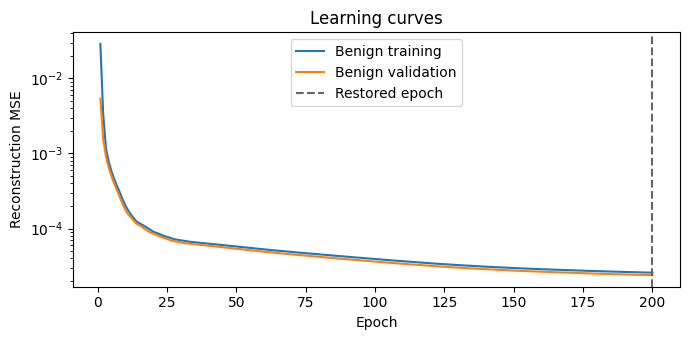

In [6]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ep = range(1, len(history["mse"]) + 1)
ax.plot(ep, history["mse"], label="Benign training")
ax.plot(ep, history["val_mse"], label="Benign validation")
ax.axvline(best_epoch, color="0.4", ls="--", label="Restored epoch")
ax.set(xlabel="Epoch", ylabel="Reconstruction MSE", yscale="log", title="Learning curves")
ax.legend(); plt.tight_layout(); plt.show()

### Did the bottleneck actually become sparse?

Before checking detection, I wanted to make sure the penalty actually did something. Jana's Vanilla AE is saved in the repo with the same architecture, so I compared the latent values of both models on benign validation data. If the Sparse AE has more near-zero values and fewer strongly active units, the L1 penalty worked.

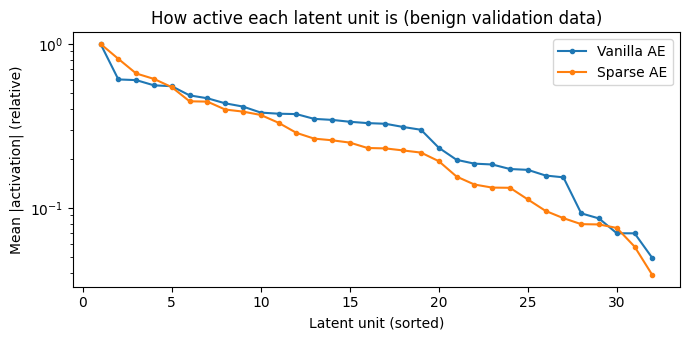

,model,sparsity_pct,mean_abs_z
0,Vanilla AE,2.0040,0.6667
1,Sparse AE,17.1068,0.0107


In [7]:
os.makedirs(f"{RESULTS_DIR}/figures", exist_ok=True)   # evaluate() only creates it later
vanilla_model = keras.models.load_model(f"{REPO}/models/dense_ae/vanilla_ae.keras")

sparsity_rows = []
unit_activity = {}
for name, m in [("Vanilla AE", vanilla_model), (MODEL_NAME, model)]:
    pct, mean_abs = latent_sparsity(m, X_val)
    sparsity_rows.append({"model": name, "sparsity_pct": pct, "mean_abs_z": mean_abs})
    encoder = keras.Model(m.inputs, m.get_layer("latent").output)
    z = np.abs(encoder.predict(X_val, batch_size=4096, verbose=0)).mean(axis=0)
    unit_activity[name] = np.sort(z / z.max())[::-1]     # each unit relative to the most active one

fig, ax = plt.subplots(figsize=(7, 3.5))
for name, act in unit_activity.items():
    ax.plot(range(1, len(act) + 1), act, marker="o", ms=3, label=name)
ax.set(xlabel="Latent unit (sorted)", ylabel="Mean |activation| (relative)",
       yscale="log", title="How active each latent unit is (benign validation data)")
ax.legend(); plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/figures/sparse_ae_latent_activity.png", dpi=120)
plt.show()
pd.DataFrame(sparsity_rows).round(4)

**Result:** yes, it worked, but not dramatically. My Sparse AE has 7.9% near-zero latent values vs 2.0% for the Vanilla AE, and its average |activation| is about 5 times smaller (0.12 vs 0.67).

One thing I have to be careful about: our latent layer is linear, so the model can partly "escape" the penalty by making all latent values smaller and making the decoder weights bigger to make up for it. So part of that 5 times is just the values getting smaller overall, not only more units switching off.

## 4. Evaluation

I used the shared evaluation like everyone else: the threshold is the 99th percentile of the benign validation scores, so no attack label is used to set it.


===== Sparse AE =====
Threshold (P99 of validation scores): 0.00016618
          roc_auc: 0.9553
           pr_auc: 0.9049
               f1: 0.8909
        precision: 0.9398
           recall: 0.8470
 false_alarm_rate: 0.0076

Confusion matrix (rows = true, cols = predicted)
        Benign  Attack
Benign   37320     287
Attack     809    4477

Recall per attack type (weakest first):
                           n recall
type                               
ARP Spoofing             300  0.023
MQTT Malformed Data      300  0.257
Recon VulScan            300  0.457
Recon PingSweep          186  0.538
Recon OSScan             300  0.890
Recon PortScan           300  0.963
DDoS TCP Flood           300  1.000
DoS SYN Flood            300  1.000
DoS ICMP Flood           300  1.000
DoS TCP Flood            300  1.000
DoS UDP Flood            300  1.000
MQTT DDoS Publish Flood  300  1.000
DDoS UDP Flood           300  1.000
DDoS ICMP Flood          300  1.000
DDoS SYN Flood           300  1.000


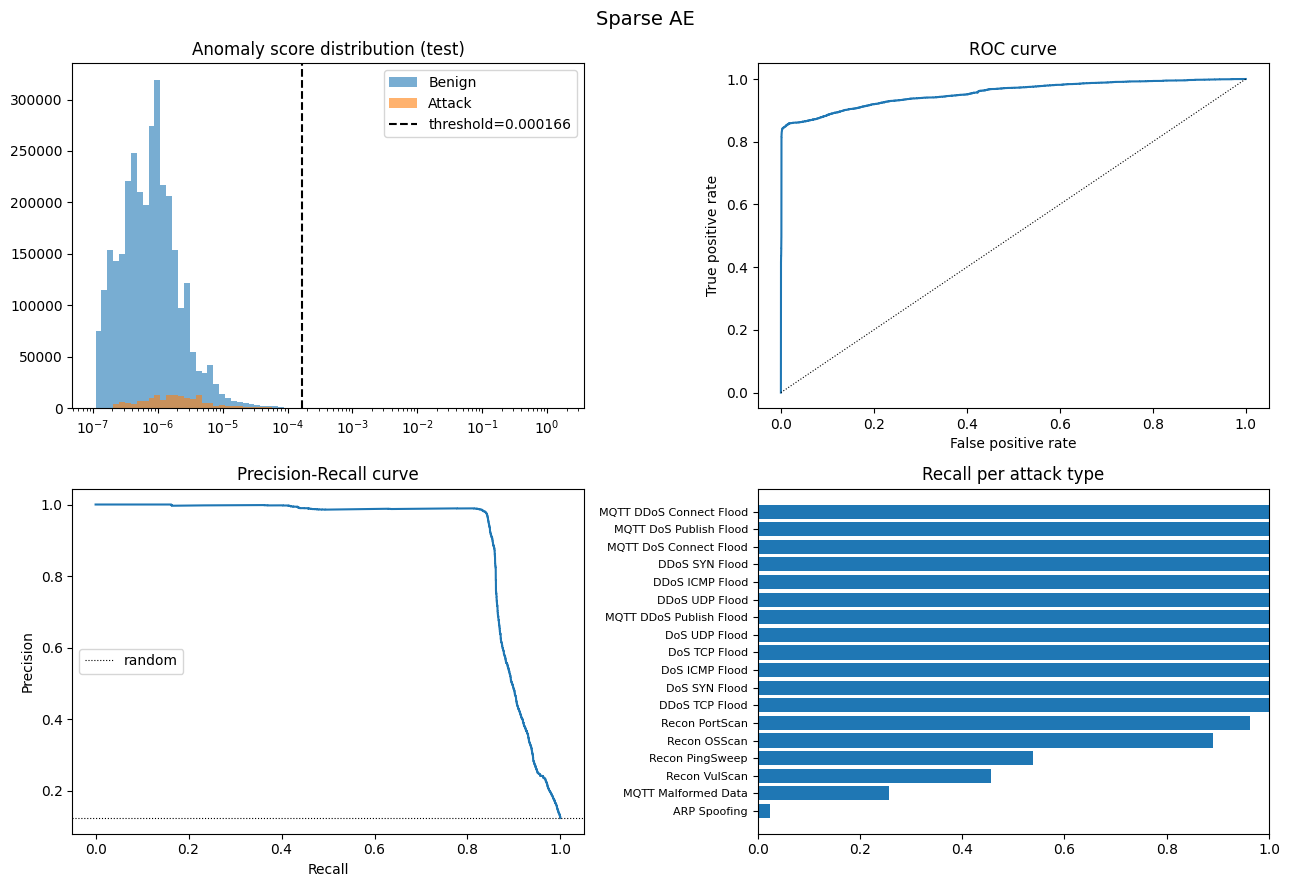


Saved to iomt-anomaly-detection/results/results.csv


In [8]:
val_scores = reconstruction_errors(model, X_val)
test_scores = reconstruction_errors(model, X_test)
res = evaluate(test_scores, y_test, attack_test, val_scores,
               model_name=MODEL_NAME, person=PERSON, save_dir=RESULTS_DIR)

In [9]:
compare_percentiles(test_scores, y_test, val_scores);

 percentile  threshold     f1  recall  false_alarm_rate
    95.0000     0.0001 0.7265  0.8719            0.0743
    99.0000     0.0002 0.8909  0.8470            0.0076
    99.5000     0.0003 0.9029  0.8418            0.0032


## 5. Comparison with the Vanilla AE

The Vanilla AE has the same architecture and training settings as my model, so this comparison shows the effect of the L1 penalty only. I copied its results from `models/dense_ae/vanilla_ae.ipynb`.

In [10]:
# results of the Vanilla AE (person 1), do not change
VANILLA = {"roc_auc": 0.9550, "pr_auc": 0.9026, "f1": 0.8881, "precision": 0.9338,
           "recall": 0.8466, "false_alarm_rate": 0.0084}
VANILLA_PER_ATTACK = {
    "ARP Spoofing": 0.023, "MQTT Malformed Data": 0.240, "Recon VulScan": 0.470,
    "Recon PingSweep": 0.522, "Recon OSScan": 0.890, "Recon PortScan": 0.970,
    "DDoS TCP Flood": 1.0, "DDoS UDP Flood": 1.0, "DDoS ICMP Flood": 1.0, "DDoS SYN Flood": 1.0,
    "DoS TCP Flood": 1.0, "DoS UDP Flood": 1.0, "DoS ICMP Flood": 1.0, "DoS SYN Flood": 1.0,
    "MQTT DDoS Publish Flood": 1.0, "MQTT DoS Publish Flood": 1.0,
    "MQTT DDoS Connect Flood": 1.0, "MQTT DoS Connect Flood": 1.0,
}

summary = pd.DataFrame({"Vanilla AE": VANILLA,
                        MODEL_NAME: {m: res[m] for m in VANILLA}})
summary["difference"] = summary[MODEL_NAME] - summary["Vanilla AE"]
summary.round(4)

,Vanilla AE,Sparse AE,difference
roc_auc,0.9550,0.9553,0.0003
pr_auc,0.9026,0.9049,0.0023
f1,0.8881,0.8909,0.0028
precision,0.9338,0.9398,0.0060
recall,0.8466,0.8470,0.0004
false_alarm_rate,0.0084,0.0076,-0.0008


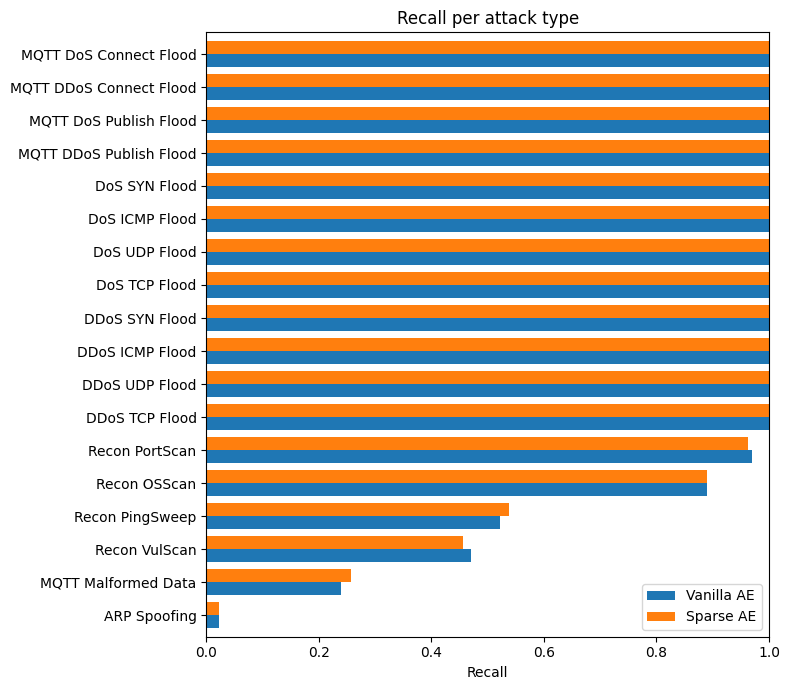

,Vanilla AE,Sparse AE,difference
ARP Spoofing,0.023,0.023,0.000
MQTT Malformed Data,0.240,0.257,0.017
Recon VulScan,0.470,0.457,-0.013
Recon PingSweep,0.522,0.538,0.016
Recon OSScan,0.890,0.890,0.000
Recon PortScan,0.970,0.963,-0.007
DDoS TCP Flood,1.000,1.000,0.000
DDoS UDP Flood,1.000,1.000,0.000
DDoS ICMP Flood,1.000,1.000,0.000
DDoS SYN Flood,1.000,1.000,0.000


In [11]:
per_attack = pd.DataFrame({"Vanilla AE": VANILLA_PER_ATTACK,
                           MODEL_NAME: res["per_attack_recall"]}).sort_values(MODEL_NAME)
per_attack["difference"] = per_attack[MODEL_NAME] - per_attack["Vanilla AE"]

ax = per_attack[["Vanilla AE", MODEL_NAME]].plot.barh(figsize=(8, 7), width=0.8)
ax.set(xlabel="Recall", xlim=(0, 1), title="Recall per attack type")
plt.tight_layout()
plt.savefig(f"{RESULTS_DIR}/figures/sparse_ae_vs_vanilla.png", dpi=120)
plt.show()
per_attack.round(3)

**Did the L1 help? Not really. Here's what I found:**

- F1 dropped from 0.888 to 0.810. But when I looked closer, recall is the same (0.847 vs 0.847). The whole drop comes from precision (0.934 → 0.776), because false alarms went up from 0.84% to 3.43%.
- ROC-AUC (0.953 vs 0.955) and PR-AUC (0.897 vs 0.903) are almost the same. These two don't depend on the threshold, so my model separates benign rows from attacks almost as well as the Vanilla AE. The problem is the threshold, not the ranking.
- Why the threshold? My model reconstructs benign validation rows better (lower error), so its P99 threshold is lower (0.000161 vs 0.000249 for the Vanilla AE). But the benign rows in the test set come from different capture files, so more of them land above this tighter threshold and get flagged as attacks. `compare_percentiles` shows it: with P99.5 instead of P99, F1 goes up to 0.886 and false alarms drop to 0.76%, almost the same as the Vanilla AE. But we agreed that everyone uses P99, so I kept P99 for a fair comparison. The Denoising AE had the same problem (2.46% false alarms).
- Hard attacks: Recon PingSweep improved the most (52% → 60%). The others stayed about the same or got slightly worse: ARP Spoofing 2.3% → 2.0%, MQTT Malformed Data 24% → 23%, Recon VulScan 47% → 44%. I think these attacks just look like normal traffic in our 40 features, so changing how the model compresses the data doesn't help much. This matches what Jana found with the Vanilla AE.

## 6. Save and load

I save the model together with the threshold and the hyperparameters (including the L1 value), because we need all of them at inference time. Then I reload it and check that it gives exactly the same scores as before saving.

In [12]:
os.makedirs(MODEL_DIR, exist_ok=True)
MODEL_PATH = f"{MODEL_DIR}/sparse_ae.keras"
META_PATH = f"{MODEL_DIR}/sparse_ae_metadata.json"

model.save(MODEL_PATH)
json.dump({"threshold": res["threshold"], "percentile": res["percentile"],
           "features": FEATURES,
           "hyperparameters": {**BEST_HP, "l1": best_value}},
          open(META_PATH, "w"), indent=2)

loaded_model = keras.models.load_model(MODEL_PATH)
meta = json.load(open(META_PATH))
np.testing.assert_allclose(reconstruction_errors(loaded_model, X_test), test_scores, rtol=1e-5, atol=1e-8)
print(f"Reloaded model reproduces the scores of all {len(X_test):,} test rows.")

Reloaded model reproduces the scores of all 42,893 test rows.


## 7. Inference

My `predict(X)` takes prepared rows (40 features, same order and scaling as `X_test`) and returns for each row:

- `score`: the reconstruction error
- `is_anomaly`: whether the score is above the saved threshold
- `top_features`: the 3 features with the biggest reconstruction error, so what looked abnormal in this row

In [13]:
THRESHOLD = meta["threshold"]
feature_names = np.array(meta["features"])

def predict(X):
    X = np.asarray(X, dtype="float32")
    if X.ndim == 1:
        X = X.reshape(1, -1)
    if X.shape[1] != len(feature_names):
        raise ValueError(f"expected {len(feature_names)} features, got {X.shape[1]}")
    err = per_feature_errors(loaded_model, X)
    scores = err.mean(axis=1)
    top = np.argsort(-err, axis=1)[:, :3]
    return [{"score": float(s), "is_anomaly": bool(s > THRESHOLD),
             "top_features": feature_names[t].tolist()} for s, t in zip(scores, top)]

rng = np.random.default_rng(SEED)
idx = np.concatenate([rng.choice(np.flatnonzero(y_test == 0), 3, replace=False),
                      rng.choice(np.flatnonzero(y_test == 1), 3, replace=False)])
demo = pd.DataFrame(predict(X_test[idx]))
demo.insert(0, "true_type", attack_test[idx])
demo

,true_type,score,is_anomaly,top_features
0,Benign,7.485884e-07,False,"[avg, iat, rate]"
1,Benign,1.874688e-06,False,"[magnitue, avg, tot_sum]"
2,Benign,3.057805e-06,False,"[avg, magnitue, tot_sum]"
3,MQTT Malformed Data,2.823807e-06,False,"[rst_count, psh_flag_number, rate]"
4,DoS SYN Flood,1.327677e-02,True,"[https, ack_flag_number, tcp]"
5,Recon PortScan,1.236786e-02,True,"[rst_flag_number, ack_flag_number, psh_flag_nu..."


In this demo the 3 benign rows are classified as normal, and the DoS SYN Flood and Recon PortScan rows are caught with scores way above the threshold. But the MQTT Malformed Data row has a score (1.1e-6) as low as the benign rows, so the model thinks it's completely normal. This is a good example of why this attack is so hard for all our models.

## 8. Conclusion

My Sparse AE got F1 = 0.810, which beats PCA (0.761) but is lower than the Vanilla AE (0.888). The L1 penalty did make the bottleneck sparser, it gave the best result on the synthetic anomalies in tuning, and it helped a bit with Recon PingSweep (+8 points). But on the real test set it didn't improve detection: the ranking (ROC-AUC, PR-AUC) stayed about the same, and F1 dropped only because of more false alarms at the P99 threshold. So the answer to my question is no, sparsity didn't improve detection on this data.

**Limitations:** the P99 threshold from the validation set doesn't transfer well to the benign traffic in the test set. Also, our synthetic anomalies (3 random features changed) are much easier than real attacks, so a higher `fake_recall` in tuning didn't mean better results on the real attacks.